<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mixing Matrix A:
 [[1.  1.  1. ]
 [0.5 2.  1. ]
 [1.5 1.  2. ]] 



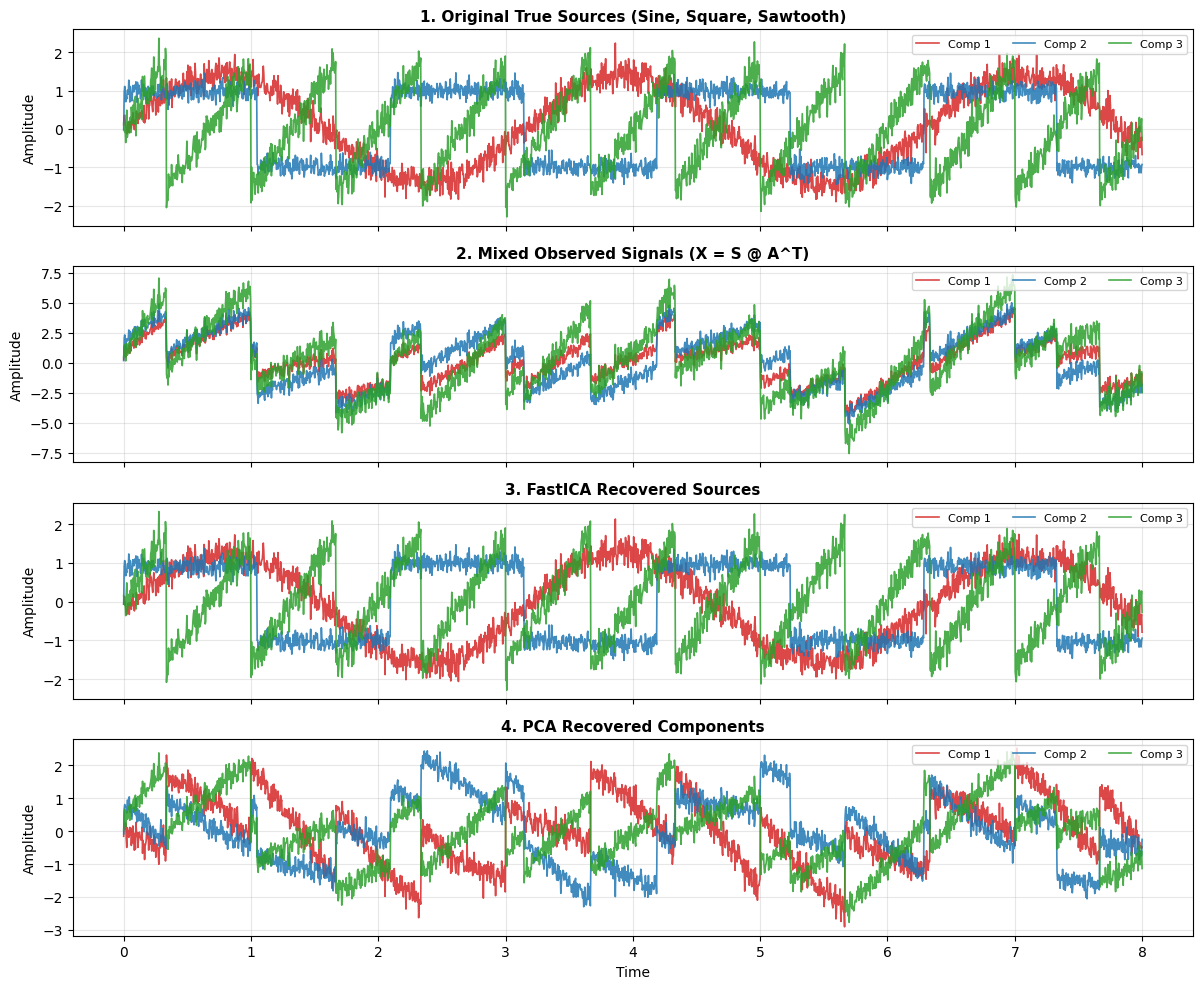

=== Task 5: Recovery Quality (|Correlation| with True Sources) ===
True Source            |  FastICA |r| |    PCA |r|
--------------------------------------------------
Source 1 (Sine)        |       0.9986 |     0.7389
Source 2 (Square)      |       0.9996 |     0.7698
Source 3 (Sawtooth)    |       0.9997 |     0.6332
--------------------------------------------------
Mean |Correlation|     |       0.9993 |     0.7140


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA, PCA

# Reproducibility
np.random.seed(42)

# ==========================================
# Task 1: Generate Source Signals (Sine, Square, Sawtooth) & Mix Them
# ==========================================
n_samples = 2000
time = np.linspace(0, 8, n_samples)

s1 = np.sin(2 * time)                              # Signal 1: Sine wave
s2 = np.sign(np.sin(3 * time))                     # Signal 2: Square wave
s3 = 2 * (time * 1.5 - np.floor(0.5 + time * 1.5)) # Signal 3: Sawtooth wave

S = np.c_[s1, s2, s3]
S += 0.15 * np.random.normal(size=S.shape)         # Add small observation noise
S /= S.std(axis=0)                                 # Standardize true sources

# Mix signals using a random 3x3 mixing matrix A
A = np.array([
    [1.0, 1.0, 1.0],
    [0.5, 2.0, 1.0],
    [1.5, 1.0, 2.0]
])
X = S @ A.T  # Mixed observations (shape: 2000 x 3)

print("Mixing Matrix A:\n", A, "\n")

# ==========================================
# Task 2: Apply FastICA to Recover Independent Sources
# ==========================================
ica = FastICA(n_components=3, random_state=42, whiten="unit-variance")
S_ica = ica.fit_transform(X)
S_ica /= S_ica.std(axis=0)

# ==========================================
# Task 3: Apply PCA to the Same Mixtures for Comparison
# ==========================================
pca = PCA(n_components=3, random_state=42)
S_pca = pca.fit_transform(X)
S_pca /= S_pca.std(axis=0)

# ==========================================
# Helper: Align Recovered Components (Order & Sign) for Clear Plotting/Metrics
# ==========================================
def align_and_score(S_true, S_est):
    """Match each estimated component to its best-correlated true source."""
    n_comp = S_true.shape[1]
    corr_mat = np.abs(np.corrcoef(S_true.T, S_est.T)[:n_comp, n_comp:])
    aligned = np.zeros_like(S_est)
    scores = []
    used = set()
    for i in range(n_comp):
        # Pick highest-correlated unused estimated component
        best_j = max((j for j in range(n_comp) if j not in used), key=lambda j: corr_mat[i, j])
        used.add(best_j)
        sign = np.sign(np.corrcoef(S_true[:, i], S_est[:, best_j])[0, 1])
        aligned[:, i] = sign * S_est[:, best_j]
        scores.append(corr_mat[i, best_j])
    return aligned, scores

S_ica_aligned, ica_corrs = align_and_score(S, S_ica)
S_pca_aligned, pca_corrs = align_and_score(S, S_pca)

# ==========================================
# Task 4: Plot Original, Mixed, ICA-Recovered & PCA-Recovered Signals
# ==========================================
models = [
    ("1. Original True Sources (Sine, Square, Sawtooth)", S),
    ("2. Mixed Observed Signals (X = S @ A^T)", X),
    ("3. FastICA Recovered Sources", S_ica_aligned),
    ("4. PCA Recovered Components", S_pca_aligned)
]
colors = ["tab:red", "tab:blue", "tab:green"]

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (title, signals) in zip(axes, models):
    for i, color in enumerate(colors):
        ax.plot(time, signals[:, i], color=color, linewidth=1.2, alpha=0.85, label=f"Comp {i+1}")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right", ncol=3, fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Measure Recovery Quality (Correlation to True Sources)
# ==========================================
source_names = ["Source 1 (Sine)", "Source 2 (Square)", "Source 3 (Sawtooth)"]
print("=== Task 5: Recovery Quality (|Correlation| with True Sources) ===")
print(f"{'True Source':22s} | {'FastICA |r|':>12s} | {'PCA |r|':>10s}")
print("-" * 50)
for name, c_ica, c_pca in zip(source_names, ica_corrs, pca_corrs):
    print(f"{name:22s} | {c_ica:12.4f} | {c_pca:10.4f}")
print("-" * 50)
print(f"{'Mean |Correlation|':22s} | {np.mean(ica_corrs):12.4f} | {np.mean(pca_corrs):10.4f}")